# Inciso 2: Tutorial de MLflow en Jupyter

Tutorial seguido: *MLflow with Optuna: Hyperparameter Optimization and Tracking*.
El notebook tiene dos partes:

1. **Tutorial original** (con correcciones mínimas de compatibilidad con pandas 3): datos sintéticos de demanda de manzanas, XGBoost y Optuna, con un run hijo de MLflow por cada prueba.
2. **Inciso 2a, mejoras al algoritmo**: cada mejora se registra como un run nuevo en el mismo experimento para poder compararlas en la interfaz.

Requiere el servidor de MLflow activo:

```bash
mlflow server --backend-store-uri sqlite:///mlflow.db --default-artifact-root ./mlartifacts --port 5000
```

In [1]:
import logging
import math
import os
import warnings
from datetime import datetime, timedelta

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import xgboost as xgb
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

import mlflow

N_TRIALS = 100
SEED = 42
VALIDATION_FRACTION = 0.25
TRACKING_URI = "http://127.0.0.1:5000"
EXPERIMENT_NAME = "Apples Demand"

mlflow.set_tracking_uri(TRACKING_URI)
optuna.logging.set_verbosity(optuna.logging.ERROR)
warnings.filterwarnings("ignore")
logging.getLogger("mlflow").setLevel(logging.ERROR)
xgb.set_config(verbosity=0)

## 1. Datos sintéticos

Función del tutorial. Cambios respecto al original, solo por compatibilidad con pandas 3:
`fillna(..., inplace=True)` sobre una columna ya no modifica el DataFrame, así que se reasigna la columna.
La lógica de generación no cambia.

In [2]:
def generate_apple_sales_data_with_promo_adjustment(
    base_demand: int = 1000,
    n_rows: int = 5000,
    competitor_price_effect: float = -50.0,
):
    np.random.seed(9999)

    dates = [datetime.now() - timedelta(days=i) for i in range(n_rows)]
    dates.reverse()

    df = pd.DataFrame(
        {
            "date": dates,
            "average_temperature": np.random.uniform(10, 35, n_rows),
            "rainfall": np.random.exponential(5, n_rows),
            "weekend": [(date.weekday() >= 5) * 1 for date in dates],
            "holiday": np.random.choice([0, 1], n_rows, p=[0.97, 0.03]),
            "price_per_kg": np.random.uniform(0.5, 3, n_rows),
            "month": [date.month for date in dates],
        }
    )

    df["inflation_multiplier"] = 1 + (df["date"].dt.year - df["date"].dt.year.min()) * 0.03

    df["harvest_effect"] = np.sin(2 * np.pi * (df["month"] - 3) / 12) + np.sin(
        2 * np.pi * (df["month"] - 9) / 12
    )

    df["price_per_kg"] = df["price_per_kg"] - df["harvest_effect"] * 0.5

    peak_months = [4, 10]
    df["promo"] = np.where(
        df["month"].isin(peak_months),
        1,
        np.random.choice([0, 1], n_rows, p=[0.85, 0.15]),
    )

    base_price_effect = -df["price_per_kg"] * 50
    seasonality_effect = df["harvest_effect"] * 50
    promo_effect = df["promo"] * 200
    df["demand"] = (
        base_demand
        + base_price_effect
        + seasonality_effect
        + promo_effect
        + df["weekend"] * 300
        + np.random.normal(0, 50, n_rows)
    ) * df["inflation_multiplier"]

    df["previous_days_demand"] = df["demand"].shift(1).bfill()

    df["competitor_price_per_kg"] = np.random.uniform(0.5, 3, n_rows)
    df["competitor_price_effect"] = (
        df["competitor_price_per_kg"] < df["price_per_kg"]
    ) * competitor_price_effect

    log_decay = -np.log(df["price_per_kg"].shift(3) + 1) + 2
    df["stock_available"] = np.clip(log_decay, 0.7, 1)

    high_stock_indices = df[df["stock_available"] > 0.95].index
    for idx in high_stock_indices:
        df.loc[idx : min(idx + 7, n_rows - 1), "marketing_intensity"] = np.random.uniform(0.7, 1)

    fill_values = pd.Series(np.random.uniform(0, 0.5, n_rows), index=df.index)
    df["marketing_intensity"] = df["marketing_intensity"].fillna(fill_values)

    df["demand"] = df["demand"] + df["competitor_price_effect"] + df["marketing_intensity"]

    df.drop(
        columns=[
            "inflation_multiplier",
            "harvest_effect",
            "month",
            "competitor_price_effect",
            "stock_available",
        ],
        inplace=True,
    )

    return df


df = generate_apple_sales_data_with_promo_adjustment(base_demand=1_000, n_rows=5000)
df.head()

,date,average_temperature,rainfall,weekend,holiday,price_per_kg,promo,demand,previous_days_demand,competitor_price_per_kg,marketing_intensity
0,2013-02-04 17:24:38.424734,30.584727,1.199291,0,0,1.726258,0,851.375336,851.276659,1.935346,0.098677
1,2013-02-05 17:24:38.424733,15.465069,1.037626,0,0,0.576471,0,906.855943,851.276659,2.344720,0.019318
2,2013-02-06 17:24:38.424733,10.786525,5.656089,0,0,2.513328,0,808.304909,906.836626,0.998803,0.409485
3,2013-02-07 17:24:38.424733,23.648154,12.030937,0,0,1.839225,0,799.833810,857.895424,0.761740,0.872803
4,2013-02-08 17:24:38.424732,13.861391,4.303812,0,0,1.531772,0,983.949061,848.961007,2.123436,0.820779


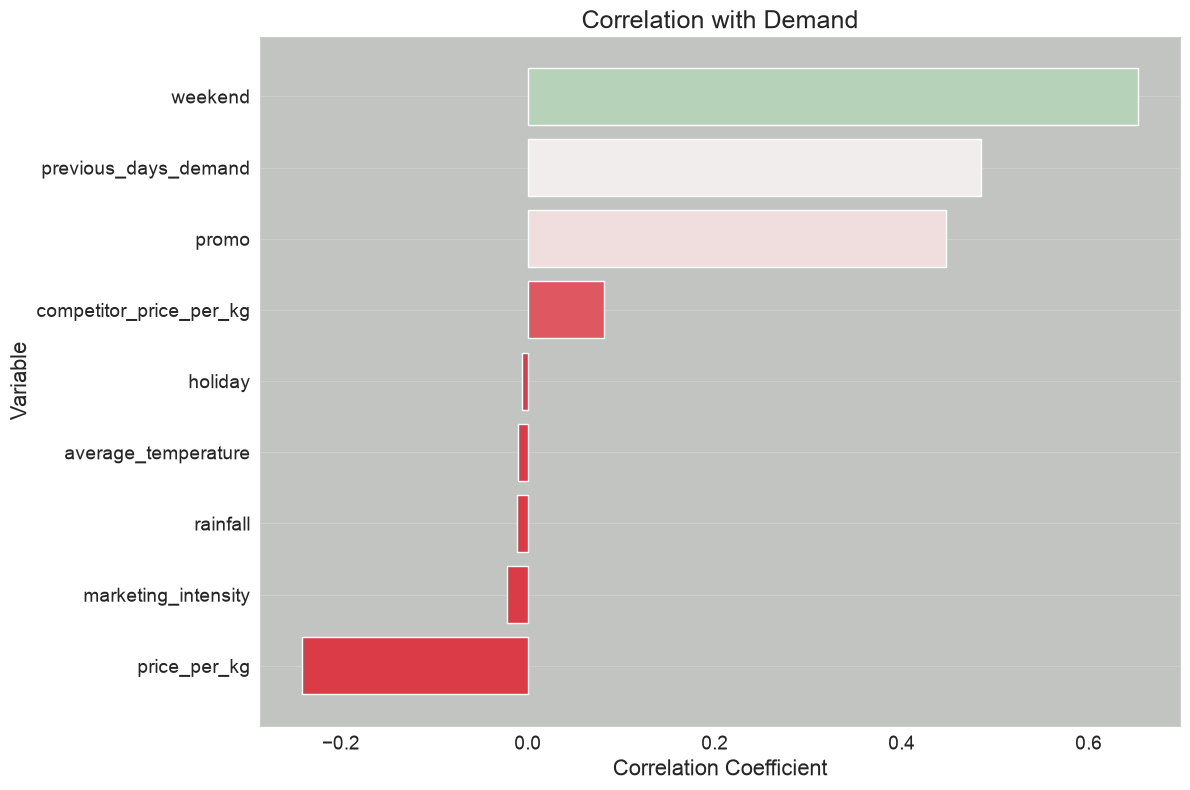

In [3]:
def plot_correlation_with_demand(df, save_path=None):
    correlations = df.drop(columns=["date"]).corr()["demand"].drop("demand").sort_values()
    colors = sns.diverging_palette(10, 130, as_cmap=True)
    color_mapped = correlations.map(colors)

    sns.set_style("whitegrid", {"axes.facecolor": "#c2c4c2", "grid.linewidth": 1.5})
    fig = plt.figure(figsize=(12, 8))
    plt.barh(correlations.index, correlations.values, color=color_mapped)
    plt.title("Correlation with Demand", fontsize=18)
    plt.xlabel("Correlation Coefficient", fontsize=16)
    plt.ylabel("Variable", fontsize=16)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.grid(axis="x")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, format="png", dpi=150)
    plt.close(fig)
    return fig


def plot_residuals(model, dvalid, valid_y, scale=1.0):
    residuals = valid_y - model.predict(dvalid) * scale
    sns.set_style("whitegrid", {"axes.facecolor": "#c2c4c2", "grid.linewidth": 1.5})
    fig = plt.figure(figsize=(12, 8))
    plt.scatter(valid_y, residuals, color="blue", alpha=0.5)
    plt.axhline(y=0, color="r", linestyle="-")
    plt.title("Residuals vs True Values", fontsize=18)
    plt.xlabel("True Values", fontsize=16)
    plt.ylabel("Residuals", fontsize=16)
    plt.grid(axis="y")
    plt.tight_layout()
    plt.close(fig)
    return fig


def plot_feature_importance(model, booster):
    fig, ax = plt.subplots(figsize=(10, 8))
    importance_type = "weight" if booster == "gblinear" else "gain"
    xgb.plot_importance(
        model,
        importance_type=importance_type,
        ax=ax,
        title=f"Feature Importance based on {importance_type}",
    )
    plt.tight_layout()
    plt.close(fig)
    return fig


correlation_plot = plot_correlation_with_demand(df)
correlation_plot

## 2. Experimento y tutorial original

El tutorial divide 75/25 sin semilla y entrena con `xgb.train` usando los 10 rounds por defecto.
Aquí se agrega solo `random_state=SEED` en la división para que el run se pueda repetir, y se reduce a `N_TRIALS = 100` pruebas (el original usa 500).

In [4]:
def get_or_create_experiment(experiment_name):
    if experiment := mlflow.get_experiment_by_name(experiment_name):
        return experiment.experiment_id
    return mlflow.create_experiment(experiment_name)


experiment_id = get_or_create_experiment(EXPERIMENT_NAME)
mlflow.set_experiment(experiment_id=experiment_id)
experiment_id

'1'

In [5]:
X = df.drop(columns=["date", "demand"])
y = df["demand"]
train_x, valid_x, train_y, valid_y = train_test_split(
    X, y, test_size=VALIDATION_FRACTION, random_state=SEED
)
dtrain = xgb.DMatrix(train_x, label=train_y)
dvalid = xgb.DMatrix(valid_x, label=valid_y)


def champion_callback(study, frozen_trial):
    winner = study.user_attrs.get("winner", None)
    if study.best_value and winner != study.best_value:
        study.set_user_attr("winner", study.best_value)
        if winner:
            improvement_percent = (abs(winner - study.best_value) / study.best_value) * 100
            print(
                f"Trial {frozen_trial.number} achieved value: {frozen_trial.value} with "
                f"{improvement_percent: .4f}% improvement"
            )
        else:
            print(f"Initial trial {frozen_trial.number} achieved value: {frozen_trial.value}")


def objective(trial):
    with mlflow.start_run(nested=True):
        params = {
            "objective": "reg:squarederror",
            "eval_metric": "rmse",
            "booster": trial.suggest_categorical("booster", ["gbtree", "gblinear", "dart"]),
            "lambda": trial.suggest_float("lambda", 1e-8, 1.0, log=True),
            "alpha": trial.suggest_float("alpha", 1e-8, 1.0, log=True),
        }

        if params["booster"] in ("gbtree", "dart"):
            params["max_depth"] = trial.suggest_int("max_depth", 1, 9)
            params["eta"] = trial.suggest_float("eta", 1e-8, 1.0, log=True)
            params["gamma"] = trial.suggest_float("gamma", 1e-8, 1.0, log=True)
            params["grow_policy"] = trial.suggest_categorical(
                "grow_policy", ["depthwise", "lossguide"]
            )

        bst = xgb.train(params, dtrain)
        preds = bst.predict(dvalid)
        error = mean_squared_error(valid_y, preds)

        mlflow.log_params(params)
        mlflow.log_metric("mse", error)
        mlflow.log_metric("rmse", math.sqrt(error))

    return error

In [6]:
with mlflow.start_run(experiment_id=experiment_id, run_name="tutorial_original"):
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=N_TRIALS, callbacks=[champion_callback])

    mlflow.log_params({f"best_{key}": value for key, value in study.best_params.items()})
    mlflow.log_param("n_trials", N_TRIALS)
    mlflow.log_param("split", "random")
    mlflow.log_metric("best_mse", study.best_value)
    mlflow.log_metric("best_rmse", math.sqrt(study.best_value))

    mlflow.set_tags(
        {
            "project": "Apple Demand Project",
            "optimizer_engine": "optuna",
            "model_family": "xgboost",
            "feature_set_version": 1,
            "variant": "tutorial_original",
        }
    )

    model = xgb.train(study.best_params, dtrain)

    mlflow.log_figure(figure=correlation_plot, artifact_file="correlation_plot.png")
    importances = plot_feature_importance(model, booster=study.best_params.get("booster"))
    mlflow.log_figure(figure=importances, artifact_file="feature_importances.png")
    residuals = plot_residuals(model, dvalid, valid_y)
    mlflow.log_figure(figure=residuals, artifact_file="residuals.png")

    mlflow.xgboost.log_model(
        xgb_model=model,
        name="model",
        input_example=train_x.iloc[[0]],
        model_format="ubj",
    )
    tutorial_run_id = mlflow.active_run().info.run_id

print("best rmse (random split):", math.sqrt(study.best_value))

Initial trial 0 achieved value: 19685.675634889958
Trial 1 achieved value: 17532.766985478927 with  12.2793% improvement


Trial 15 achieved value: 16838.56760479115 with  4.1227% improvement
Trial 18 achieved value: 16471.84584701484 with  2.2264% improvement


Trial 25 achieved value: 15878.628632776205 with  3.7359% improvement


Trial 37 achieved value: 15621.146694156814 with  1.6483% improvement


Trial 67 achieved value: 15584.736144341314 with  0.2336% improvement


Trial 69 achieved value: 15474.581373798635 with  0.7118% improvement


best rmse (random split): 124.3968704341015


In [7]:
model_uri = f"runs:/{tutorial_run_id}/model"
loaded = mlflow.xgboost.load_model(model_uri)
infer_df = df.copy()
infer_df["predicted_demand"] = loaded.predict(xgb.DMatrix(X))
infer_df[["date", "demand", "predicted_demand"]].tail()

,date,demand,predicted_demand
4995,2026-10-09 17:24:38.422701,1418.210762,1300.753662
4996,2026-10-10 17:24:38.422700,1980.149505,1705.146118
4997,2026-10-11 17:24:38.422700,1660.171368,1787.290771
4998,2026-10-12 17:24:38.422699,1646.369501,1508.031616
4999,2026-10-13 17:24:38.422696,1539.301286,1320.753174


## 3. Inciso 2a: análisis del algoritmo y mejoras

### Problemas detectados en el tutorial

1. **División aleatoria con datos de serie de tiempo.** Los datos son diarios y existe `previous_days_demand`. Una división aleatoria mezcla días futuros en el set de entrenamiento y el error de validación sale optimista. En producción solo se conoce el pasado, así que lo correcto es validar con los últimos días (división cronológica).
2. **Sin semilla en la división.** Cada ejecución da un resultado distinto y no se pueden comparar runs. Se fija `random_state` y la semilla del sampler de Optuna.
3. **Espacio de búsqueda desperdiciado.** `eta` va de 1e-8 a 1 en escala logarítmica. Con solo 10 rounds por defecto, un `eta` pequeño deja el modelo sin entrenar. Además `xgb.train` usa 10 rounds fijos: el número de árboles no se busca.
4. **Información descartada.** El generador elimina la columna `month` aunque la demanda tiene estacionalidad anual. El modelo recibe temperatura y precio pero no la época del año.
5. **Sin modelo de referencia.** No hay forma de saber si XGBoost aporta algo frente a un modelo simple.
6. **Ruido de `marketing_intensity`.** Se suma directamente a la demanda con valores entre 0 y 1, contra una demanda de ~1000. Su efecto es casi nulo, aunque el nombre sugiere una variable importante. Es un defecto del generador, no del modelo.

### Experimentos

Para comparar de forma justa, todo lo siguiente se evalúa en el **mismo conjunto de validación cronológico** (el último 25 por ciento de los días):

| Run | Qué cambia |
|---|---|
| `baseline_linear_regression` | Modelo de referencia sin búsqueda de hiperparámetros |
| `tutorial_space_chronological` | Mismo espacio de búsqueda del tutorial, pero con división cronológica |
| `improved_search` | Espacio de búsqueda corregido, número de rounds con early stopping y variables `month` y `day_of_week` |
| `improved_detrended` | Lo anterior, más la variable `year_index` y un objetivo sin tendencia (ver abajo) |

**Por qué se quita la tendencia.** La demanda se multiplica por un factor de inflación que crece cada año, y la validación cronológica cae en años que el modelo no vio. Un árbol de decisión predice promedios de lo que vio en entrenamiento, así que no puede extrapolar un nivel más alto. La solución es estimar el crecimiento anual con una regresión simple sobre el set de entrenamiento, entrenar con `demand / (1 + crecimiento * year_index)` y volver a multiplicar al predecir.

In [8]:
split_index = int(len(df) * (1 - VALIDATION_FRACTION))
chrono_train, chrono_valid = df.iloc[:split_index], df.iloc[split_index:]


def add_year_index(frame):
    return frame.assign(year_index=frame["date"].dt.year - df["date"].dt.year.min())


def to_features(frame, with_month, with_year=False):
    features = frame.drop(columns=["date", "demand"])
    if with_month:
        features = features.assign(month=frame["date"].dt.month, day_of_week=frame["date"].dt.dayofweek)
    if with_year:
        features = features.assign(year_index=add_year_index(frame)["year_index"])
    return features


def estimate_trend_scaler(train_frame):
    indexed = add_year_index(train_frame)
    trend = LinearRegression().fit(indexed[["year_index"]], indexed["demand"])
    yearly_growth = trend.coef_[0] / trend.intercept_
    return lambda frame: 1 + yearly_growth * add_year_index(frame)["year_index"].to_numpy()


def log_common_metrics(prefix, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    mlflow.log_metric(f"{prefix}mse", mse)
    mlflow.log_metric(f"{prefix}rmse", math.sqrt(mse))
    return mse

In [9]:
with mlflow.start_run(experiment_id=experiment_id, run_name="baseline_linear_regression"):
    linear = LinearRegression().fit(to_features(chrono_train, with_month=False), chrono_train["demand"])
    preds = linear.predict(to_features(chrono_valid, with_month=False))
    mlflow.log_param("split", "chronological")
    mlflow.log_param("model", "LinearRegression")
    mlflow.set_tag("variant", "baseline_linear_regression")
    baseline_mse = log_common_metrics("best_", chrono_valid["demand"], preds)
    mlflow.sklearn.log_model(linear, name="model", input_example=to_features(chrono_valid, False).iloc[[0]])

print("baseline rmse:", math.sqrt(baseline_mse))

baseline rmse: 197.92276113774346


In [10]:
def run_search(run_name, suggest_params, with_month, use_early_stopping, detrend=False):
    train_x_c = to_features(chrono_train, with_month, with_year=detrend)
    valid_x_c = to_features(chrono_valid, with_month, with_year=detrend)
    scaler = estimate_trend_scaler(chrono_train) if detrend else (lambda frame: np.ones(len(frame)))
    train_scale, valid_scale = scaler(chrono_train), scaler(chrono_valid)
    dtrain_c = xgb.DMatrix(train_x_c, label=chrono_train["demand"] / train_scale)
    dvalid_c = xgb.DMatrix(valid_x_c, label=chrono_valid["demand"] / valid_scale)

    def train_booster(params, num_boost_round):
        if use_early_stopping:
            return xgb.train(
                params,
                dtrain_c,
                num_boost_round=num_boost_round,
                evals=[(dvalid_c, "valid")],
                early_stopping_rounds=30,
                verbose_eval=False,
            )
        return xgb.train(params, dtrain_c)

    def search_objective(trial):
        params, num_boost_round = suggest_params(trial)
        with mlflow.start_run(nested=True):
            booster = train_booster(params, num_boost_round)
            error = mean_squared_error(chrono_valid["demand"], booster.predict(dvalid_c) * valid_scale)
            mlflow.log_params({**params, "num_boost_round": num_boost_round})
            mlflow.log_metric("mse", error)
            mlflow.log_metric("rmse", math.sqrt(error))
            if use_early_stopping:
                mlflow.log_metric("best_iteration", booster.best_iteration)
        return error

    with mlflow.start_run(experiment_id=experiment_id, run_name=run_name):
        study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
        study.optimize(search_objective, n_trials=N_TRIALS)

        mlflow.log_params({f"best_{key}": value for key, value in study.best_params.items()})
        mlflow.log_param("n_trials", N_TRIALS)
        mlflow.log_param("split", "chronological")
        mlflow.log_param("with_month_features", with_month)
        mlflow.log_param("early_stopping", use_early_stopping)
        mlflow.log_param("detrended_target", detrend)
        mlflow.log_metric("best_mse", study.best_value)
        mlflow.log_metric("best_rmse", math.sqrt(study.best_value))
        mlflow.set_tags({"variant": run_name, "model_family": "xgboost", "optimizer_engine": "optuna"})

        best_params, best_rounds = suggest_params(optuna.trial.FixedTrial(study.best_params))
        booster = train_booster(best_params, best_rounds)
        mlflow.log_figure(plot_feature_importance(booster, best_params["booster"]), "feature_importances.png")
        mlflow.log_figure(plot_residuals(booster, dvalid_c, chrono_valid["demand"], valid_scale), "residuals.png")
        mlflow.xgboost.log_model(booster, name="model", input_example=train_x_c.iloc[[0]], model_format="ubj")

    return study

In [11]:
def suggest_tutorial_params(trial):
    params = {
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        "booster": trial.suggest_categorical("booster", ["gbtree", "gblinear", "dart"]),
        "lambda": trial.suggest_float("lambda", 1e-8, 1.0, log=True),
        "alpha": trial.suggest_float("alpha", 1e-8, 1.0, log=True),
    }
    if params["booster"] in ("gbtree", "dart"):
        params["max_depth"] = trial.suggest_int("max_depth", 1, 9)
        params["eta"] = trial.suggest_float("eta", 1e-8, 1.0, log=True)
        params["gamma"] = trial.suggest_float("gamma", 1e-8, 1.0, log=True)
        params["grow_policy"] = trial.suggest_categorical("grow_policy", ["depthwise", "lossguide"])
    return params, 10


def suggest_improved_params(trial):
    params = {
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        "booster": trial.suggest_categorical("booster", ["gbtree", "gblinear"]),
        "lambda": trial.suggest_float("lambda", 1e-8, 10.0, log=True),
        "alpha": trial.suggest_float("alpha", 1e-8, 10.0, log=True),
    }
    if params["booster"] == "gbtree":
        params["max_depth"] = trial.suggest_int("max_depth", 1, 9)
        params["eta"] = trial.suggest_float("eta", 1e-2, 0.5, log=True)
        params["gamma"] = trial.suggest_float("gamma", 1e-8, 1.0, log=True)
        params["min_child_weight"] = trial.suggest_int("min_child_weight", 1, 10)
        params["subsample"] = trial.suggest_float("subsample", 0.5, 1.0)
        params["colsample_bytree"] = trial.suggest_float("colsample_bytree", 0.5, 1.0)
    return params, 1000


tutorial_space_study = run_search(
    "tutorial_space_chronological", suggest_tutorial_params, with_month=False, use_early_stopping=False
)
print("tutorial space, chronological rmse:", math.sqrt(tutorial_space_study.best_value))

tutorial space, chronological rmse: 200.59363651701344


In [12]:
improved_study = run_search(
    "improved_search", suggest_improved_params, with_month=True, use_early_stopping=True
)
print("improved search, chronological rmse:", math.sqrt(improved_study.best_value))

improved search, chronological rmse: 163.64856345943207


In [13]:
detrended_study = run_search(
    "improved_detrended",
    suggest_improved_params,
    with_month=True,
    use_early_stopping=True,
    detrend=True,
)
print("improved + detrended, chronological rmse:", math.sqrt(detrended_study.best_value))

improved + detrended, chronological rmse: 70.38837142351426


## 4. Resultados

In [14]:
runs = mlflow.search_runs(
    experiment_ids=[experiment_id],
    filter_string="tags.variant != ''",
    order_by=["start_time ASC"],
)
top_level = runs[runs["tags.mlflow.parentRunId"].isna()] if "tags.mlflow.parentRunId" in runs else runs
summary = top_level[["tags.mlflow.runName", "params.split", "metrics.best_rmse"]].rename(
    columns={"tags.mlflow.runName": "run", "params.split": "split", "metrics.best_rmse": "best_rmse"}
)
summary

,run,split,best_rmse
0,tutorial_original,random,124.396870
1,baseline_linear_regression,chronological,197.922761
2,tutorial_space_chronological,chronological,200.593637
3,improved_search,chronological,163.648563
4,improved_detrended,chronological,70.388371


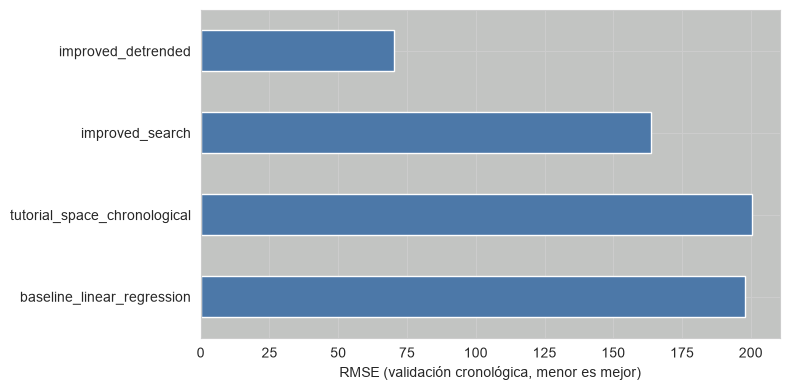

In [15]:
chrono_runs = summary[summary["split"] == "chronological"].set_index("run")["best_rmse"]
fig, ax = plt.subplots(figsize=(8, 4))
chrono_runs.plot.barh(ax=ax, color="#4c78a8")
ax.set_xlabel("RMSE (validación cronológica, menor es mejor)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Las conclusiones del análisis se escriben en `entrega.md` (sección Inciso 2a) con los números de esta ejecución.